<a href="https://colab.research.google.com/github/skarchana-ai/Machine-Learning/blob/main/Feature_Selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature Selection

Feature Selection is the process of selecting the most revelent features (columns) from a dataset while removing irrelevant, redundant or less important features.

In machine learning, feature selection helps to :

*   Improve model Performance
*   Reduce overfitting
*   Reduce training time
*   Remove unnecessary features
*   Make models simpler and easier to understand

There are three main approacges to feature selection:


1.   Filter Method
2.   Wrapper Method
3.   Embedded Method

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold,chi2,f_classif,mutual_info_classif,SelectKBest
from scipy.stats import pearsonr, spearmanr

In [2]:
data = {
    'Study_Hours': [
        2, 3, 5, 6, 1, 7, 4, 8, 2, 6,
        3, 9, 5, 1, 7, 4, 8, 2, 6, 5
    ],

    'Attendance': [
        55, 60, 80, 90, 40, 95, 75, 98, 50, 85,
        65, 99, 82, 45, 92, 70, 96, 48, 88, 78
    ],

    'Previous_Score': [
        45, 50, 75, 85, 35, 90, 65, 95, 40, 80,
        55, 98, 72, 30, 88, 60, 94, 38, 83, 70
    ],

    'Assignment_Score': [
        50, 55, 78, 88, 30, 92, 68, 96, 45, 82,
        60, 99, 75, 35, 90, 65, 95, 40, 85, 73
    ],

    'Sleep_Hours': [
        5, 6, 7, 8, 4, 7, 6, 8, 5, 7,
        6, 8, 7, 4, 8, 6, 7, 5, 8, 7
    ],

    'Internet_Access': [
        0, 1, 1, 1, 0, 1, 1, 1, 0, 1,
        1, 1, 1, 0, 1, 1, 1, 0, 1, 1
    ],

    'Extra_Coaching': [
        0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
        0, 1, 1, 0, 1, 0, 1, 0, 1, 1
    ],

    'Pass': [
        0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
        0, 1, 1, 0, 1, 0, 1, 0, 1, 1
    ]
}

In [3]:
df=pd.DataFrame(data)

In [4]:
df

,Study_Hours,Attendance,Previous_Score,Assignment_Score,Sleep_Hours,Internet_Access,Extra_Coaching,Pass
0,2,55,45,50,5,0,0,0
1,3,60,50,55,6,1,0,0
2,5,80,75,78,7,1,1,1
3,6,90,85,88,8,1,1,1
4,1,40,35,30,4,0,0,0
5,7,95,90,92,7,1,1,1
6,4,75,65,68,6,1,0,1
7,8,98,95,96,8,1,1,1
8,2,50,40,45,5,0,0,0
9,6,85,80,82,7,1,1,1


Seperate Independent and Dependent Variables

In [5]:
X=df.drop('Pass',axis=1)
y=df['Pass']

X=Independent variables(input features)

y=Dependent Variables(target/output)

In [6]:
X

,Study_Hours,Attendance,Previous_Score,Assignment_Score,Sleep_Hours,Internet_Access,Extra_Coaching
0,2,55,45,50,5,0,0
1,3,60,50,55,6,1,0
2,5,80,75,78,7,1,1
3,6,90,85,88,8,1,1
4,1,40,35,30,4,0,0
5,7,95,90,92,7,1,1
6,4,75,65,68,6,1,0
7,8,98,95,96,8,1,1
8,2,50,40,45,5,0,0
9,6,85,80,82,7,1,1


In [7]:
y

,Pass
0,0
1,0
2,1
3,1
4,0
5,1
6,1
7,1
8,0
9,1


# Filter Method

# 1. Varience threshold

Varience Threshold is a feature selection technique that removes features with very low varience.

Varience measures how much the values in a column differ from each other.

If a column contains almost the same value for every row, it provides very little information to the model.

sigma^2 = summation(x-x bar)^2 / n

In [8]:
from sklearn.feature_selection import VarianceThreshold

#Create a copy of the dataset
df_variance=X.copy()

#Add a constant column
df_variance['Constant_Feature']=5

#Add a low variance column
df_variance['Low_Variance']=[
    1,1,1,1,1,1,1,1,1,1,
    1,1,1,1,1,1,1,1,1,2
]

#Create Variance Threshold object
selector=VarianceThreshold(threshold=0.1)

#Apply feature selection
selected_data=selector.fit_transform(df_variance)

In [9]:
# Get selected column names
selected_features=df_variance.columns[
    selector.get_support()
]

print("Select Features:")
print(selected_features.tolist())

print("\n\nRemoved Features:")
print(
    df_variance.columns[
        ~selector.get_support()
        ].tolist()
)

Select Features:
['Study_Hours', 'Attendance', 'Previous_Score', 'Assignment_Score', 'Sleep_Hours', 'Internet_Access', 'Extra_Coaching']


Removed Features:
['Constant_Feature', 'Low_Variance']


# Correlation Analysis

Correlation Analysis is a statistical techinique used to identify the relationship between two or more variables.

It helps us understand whether two features are strongly related to each other.

In feature selection, correlation analysis is used to identify redundant features.

Foe example:

*   Study Hours and Assignment Score might have a strong positive relationship.
*   Attendence and Previous Score might also have a relationship.If two features contain almost the same information, we may remove one of them.

Types of Correlation:

1.   Positive
2.   Negative
3.   No Correlation

POSITIVE COORELATION

When one variable increases, the other variable also tends to increase.

NEGATIVE COORELATION

When one variable increases, the other variable tends to decrease.

NO CORRELATION

There is no clear relationship between the two variables.

Example: Student ID and Exam Marks.

When to use it?

Use Correlation analysis to identify highly correlated features and reduce redundant information in the dataset.









In [10]:
#Calculate correlation between numerical features
correlation_matrix=X.corr()

# Visualise the Correlation Matrix

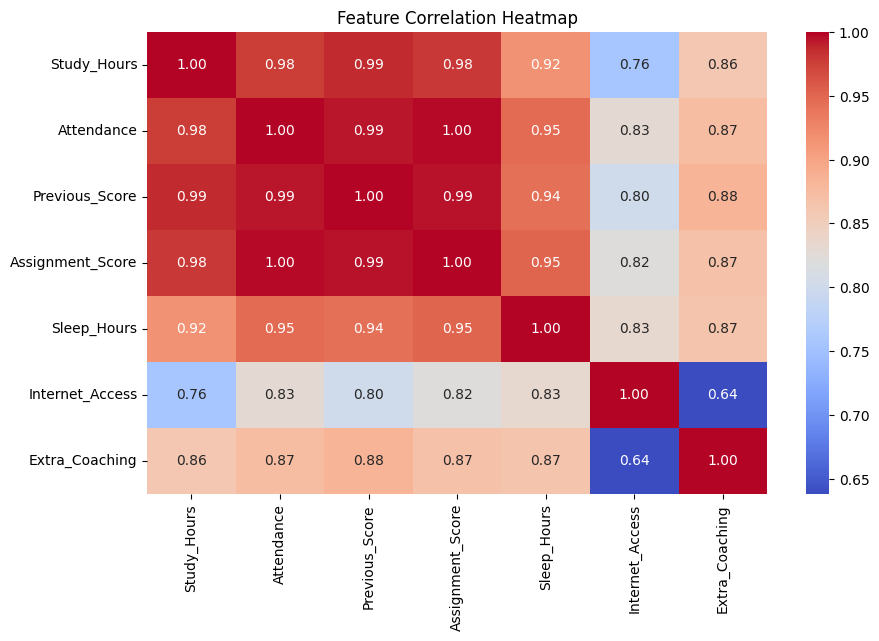

In [11]:
plt.figure(figsize=(10,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")

plt.show()

# Find Highly Correlated Features:

In [29]:
# Get the upper triangle of the correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find features having correlation above 0.80
high_correlation = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column].abs() > 0.80)
]

print("Highly Correlated Features:")
print(high_correlation)


Highly Correlated Features:
['Attendance', 'Previous_Score', 'Assignment_Score', 'Sleep_Hours', 'Internet_Access', 'Extra_Coaching']


# Remove Highly correlated features:

In [30]:
X_corr=X.drop(columns=high_correlation)

X_corr.head()

,Study_Hours
0,2
1,3
2,5
3,6
4,1


Important:

A highly correlation between two input features does not automatically mean that one shoukd be removed. Consider its relationship with the target, domain knowledge and the model being used.

# Pearson Correlation

Pearson Correlation measuresthe strength and direction of a linear relationship between two numerical variables.

It produces a correlation coefficient between -1 and +1.

In [ ]:
# Understanding Pearson Correlation:
# Value                    Meaning
# +1                       Perfect Positive Correlation
# +0.8 to +1               Strong Positive Correlation
# 0                        No Linear Correlation
# -0.8 to -1               Strong Negative Correlation
# -1                       Perfect Negative Correlation

When to use it?

Use Pearson Correlation when:

* Both variables are numerical.
* You want to identify linear relationships.
* You want to measure how strongly a feature is linearly associated with the target.





In [13]:
from scipy.stats import pearsonr

#Calculate Pearson correlation
correlation,p_value = pearsonr(
    df['Study_Hours'],
    df['Pass']
)

print("Pearson Correlation:", correlation)

print("P-value:", p_value)

Pearson Correlation: 0.8445765603251982
P-value: 2.8183141250168137e-06


# Find Pearson Correlation for all Features aganist Target:

In [15]:
pearson_scores={}

for column in X.columns:

  correlation, p_value = pearsonr(
      X[column],
      y
  )

  pearson_scores[column]=correlation

pearson_df =pd.DataFrame(
    pearson_scores.items(),
    columns=['Feature','Pearson_Correlation']
)

pearson_df.sort_values(
    by='Pearson_Correlation',
    ascending=False
)

,Feature,Pearson_Correlation
6,Extra_Coaching,0.902671
1,Attendance,0.889077
2,Previous_Score,0.885064
3,Assignment_Score,0.871787
0,Study_Hours,0.844577
4,Sleep_Hours,0.842864
5,Internet_Access,0.707107


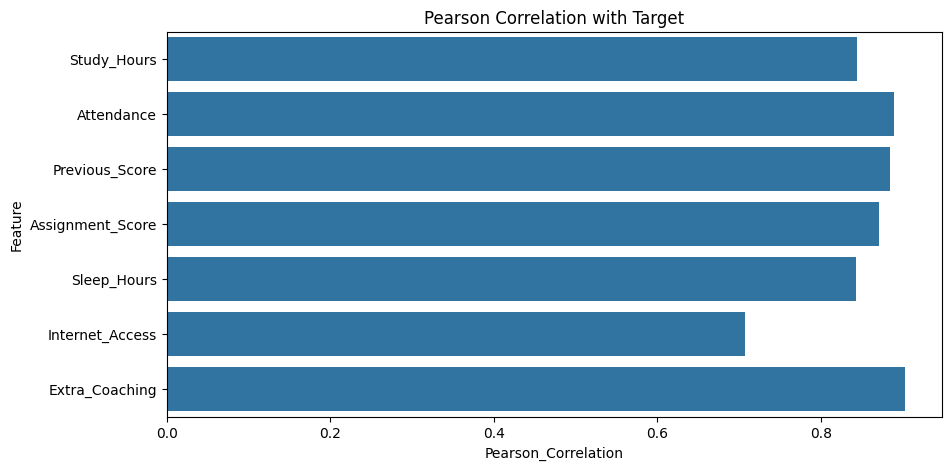

In [17]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=pearson_df,
    x='Pearson_Correlation',
    y='Feature'
    )

plt.title("Pearson Correlation with Target")

plt.show()

# Chi-Square Test

Chi-Square test is a statistical techinique used to identify the relationship between categorical features and a categorical target variable.

It Checks whether two categorical variables are indeoendent of each other.


For example:

*   Internet Access and Pass/Fail
*   Extra Coaching and Pass/Fail
*   Gender and Pass/Fail. If a feature has a significant relationship with the target,it may be useful for prediction.

When to use it?

Use Chi-Square when:

*   The target variable is categorical.
*   The input features represent categorical data or non-negative frequency/count data.
*   You want to identify relationships between categorical features and the target.

In [27]:
from sklearn.feature_selection import chi2
#Select categorical features
X_chi=df[
    ['Internet_Access','Extra_Coaching']
]

#Apply Chi-Square Test
chi_scores,p_values=chi2(X_chi,y)

#Create result DataFrame
chi_df=pd.DataFrame(
    {
        'Feature':X_chi.columns,
        'Chi_Square_Score':chi_scores,
        'P-Value':p_values
    }
)

chi_df

,Feature,Chi_Square_Score,P-Value
0,Internet_Access,2.500000,0.113846
1,Extra_Coaching,7.333333,0.006769


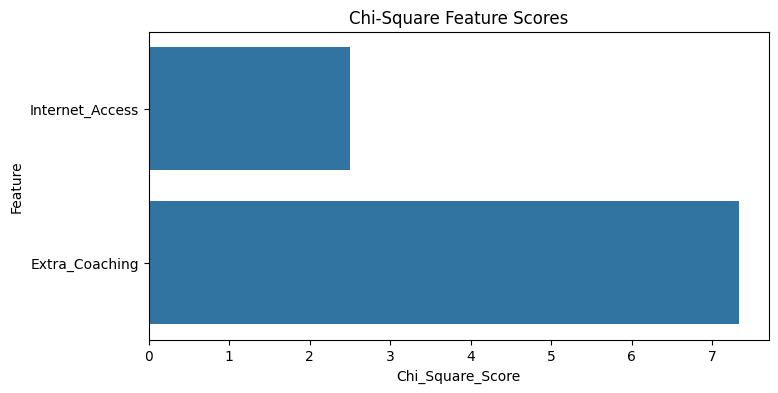

In [28]:
plt.figure(figsize=(8,4))

sns.barplot(
    data=chi_df,
    x='Chi_Square_Score',
    y='Feature'
)

plt.title("Chi-Square Feature Scores")

plt.show()